Dataset:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Dataset Shape: (442, 11)
Number of Independent Variables: 10

Original Number of Features: 10
Polynomial Features: 66

Linear Regression MSE: 3183.76
Ridge Regression MSE: 2821.05
Lasso Regression MSE: 2902.31

Actual Values:
[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.  94. 252. 

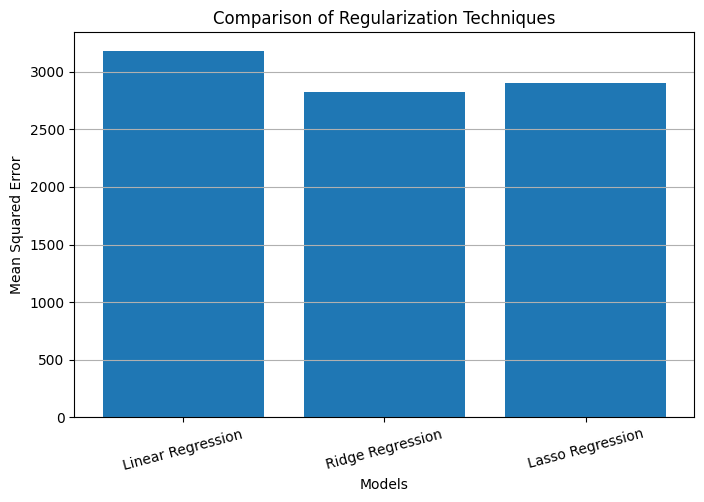


Regularization Completed Successfully


In [1]:
# Experiment 8: Regularization using Diabetes Dataset

# Import required libraries
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import pandas as pd
import matplotlib.pyplot as plt

# Load Diabetes dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Display dataset
print("Dataset:")
print(df.head())

# Independent variables
X = df.drop("target", axis=1)

# Dependent variable
y = df["target"]

print("\nDataset Shape:", df.shape)
print("Number of Independent Variables:", X.shape[1])

# Generate polynomial features
# Degree 2 is used to avoid excessive feature expansion
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

print("\nOriginal Number of Features:", X.shape[1])
print("Polynomial Features:", X_poly.shape[1])

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_poly,
    y,
    test_size=0.25,
    random_state=42
)

# Standardize polynomial features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

# Ridge Regression
ridge_model = Ridge(alpha=10)
ridge_model.fit(X_train_scaled, y_train)

# Lasso Regression
lasso_model = Lasso(
    alpha=0.1,
    max_iter=100000
)
lasso_model.fit(X_train_scaled, y_train)

# Predictions
linear_pred = linear_model.predict(X_test_scaled)
ridge_pred = ridge_model.predict(X_test_scaled)
lasso_pred = lasso_model.predict(X_test_scaled)

# Calculate Mean Squared Error
linear_mse = mean_squared_error(y_test, linear_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)

# Display results
print("\nLinear Regression MSE:", round(linear_mse, 2))
print("Ridge Regression MSE:", round(ridge_mse, 2))
print("Lasso Regression MSE:", round(lasso_mse, 2))

# Display actual and predicted values
print("\nActual Values:")
print(y_test.values)

print("\nLinear Regression Predictions:")
print(linear_pred)

print("\nRidge Regression Predictions:")
print(ridge_pred)

print("\nLasso Regression Predictions:")
print(lasso_pred)

# Compare MSE values graphically
models = [
    "Linear Regression",
    "Ridge Regression",
    "Lasso Regression"
]

mse_values = [
    linear_mse,
    ridge_mse,
    lasso_mse
]

plt.figure(figsize=(8, 5))
plt.bar(models, mse_values)

plt.xlabel("Models")
plt.ylabel("Mean Squared Error")
plt.title("Comparison of Regularization Techniques")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()

print("\nRegularization Completed Successfully")